# Industry Project: Tuning a Factory Process with Gaussian Processes and Bayesian Optimization (Production-Style)

> **Who is this notebook for?** Beginners who have heard that Gaussian processes give "predictions with error bars" and want to see **where companies actually use that**.
> No heavy math is needed: every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `01_uncommon_ml_models.ipynb`

| `01_uncommon_ml_models.ipynb` (GP section) | This notebook |
|---|---|
| What a GP is, on a 1-D toy function | A GP as a **surrogate model** of an expensive factory process with 3 settings |
| One kernel | **Choosing a kernel** (RBF vs Matern, noise term, one length-scale per setting) |
| Shows the uncertainty band | **Checks** whether the uncertainty is honest (leave-one-out coverage) |
| No decisions | Uses the uncertainty to **decide the next experiment** (Bayesian optimization with Expected Improvement) |
| | Compares against **random and grid search with the same budget**, over 10 repeats |
| | Recommends settings, saves the model, and serves predictions with input validation |

---

### The business problem

You are a process engineer at a plant that makes plastic housings by **injection molding**. A new product needs new machine settings:

| Setting | Allowed range |
|---|---|
| `melt_temp_c` (temperature of the molten plastic) | 200 to 280 °C |
| `pressure_bar` (injection pressure) | 60 to 140 bar |
| `cooling_s` (cooling time in the mold) | 10 to 40 s |

The goal is the highest **yield**: the percentage of parts that pass quality inspection. Every **experiment** (set the machine, run 200 parts, inspect them) costs about **$1,500** in material and lost production time. Management approved **20 experiments**.

With 3 settings, even a coarse grid of 5 values each would need 125 experiments. We need to be smart about **which experiment to run next**. This is exactly what **Bayesian optimization** with a **Gaussian process** does, and it is widely used in industry: process engineering, chemistry and materials labs, A/B-test parameter tuning, and hyperparameter tuning of ML models (Optuna, Ax/BoTorch, scikit-optimize).

**Success means:** find settings with a high yield within 20 experiments, and know **how sure** we are about it.

---

### Table of Contents
1. Setup: imports and one central config
2. The process: a simulator that plays the role of the real machine
3. Historical experiments and how to scale the inputs
4. A GP surrogate: choosing a sensible kernel
5. Are the error bars honest? Leave-one-out coverage
6. Expected Improvement in a few readable lines
7. The Bayesian optimization loop (20 experiments)
8. Fair comparison: BO vs random vs grid search, 10 repeats
9. Recommending the next experiments (also in parallel batches)
10. The final recommendation and confirmation runs
11. Save the surrogate with its metadata
12. Serving: predict yield for proposed settings, with input validation
13. Automated tests
14. Summary, exercises and resources

---
## 1. Setup: imports and one central config

In [1]:
# ---- Standard library ----
import copy                      # copy a fitted GP (Section 6)
import json
import logging
import tempfile                  # saved model goes to a temporary folder (never into the repo)
import time
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party ----
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import norm, qmc                     # normal distribution (for EI) and quasi-random designs
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
from threadpoolctl import threadpool_limits          # control how many CPU threads NumPy's linear algebra uses

warnings.filterwarnings("ignore")                     # GP optimizers can be chatty about convergence
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("process_bo")

# GP matrices here are tiny (at most 20 x 20). Multi-threaded linear algebra only adds overhead for such
# small problems, and on a shared server it can make things dramatically slower. One thread is fastest.
threadpool_limits(limits=1)


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    budget: int = 20                     # total experiments approved
    n_initial: int = 6                   # first experiments: a space-filling design (no model yet)
    cost_per_experiment_usd: float = 1500.0
    noise_sd: float = 1.0                # run-to-run noise of a measured yield (percentage points)
    ei_xi: float = 1.0                   # EI "exploration bonus": ~1 noise sd (smaller gains are not worth chasing)
    n_candidates: int = 4096             # candidate settings scored by EI in every round (Sobol points)
    n_repeats: int = 10                  # repeats for the BO vs random vs grid comparison


BOUNDS = {                               # the allowed range of every machine setting
    "melt_temp_c": (200.0, 280.0),
    "pressure_bar": (60.0, 140.0),
    "cooling_s": (10.0, 40.0),
}
SETTINGS = list(BOUNDS)
LOW = np.array([b[0] for b in BOUNDS.values()])
HIGH = np.array([b[1] for b in BOUNDS.values()])
CFG = Config()
log.info("scikit-learn %s", sklearn.__version__)
print(CFG)

2026-10-21 17:21:48,894 | INFO | scikit-learn 1.9.0


Config(random_state=42, budget=20, n_initial=6, cost_per_experiment_usd=1500.0, noise_sd=1.0, ei_xi=1.0, n_candidates=4096, n_repeats=10)


---
## 2. The process: a simulator that plays the role of the real machine

In real life, "evaluating" a setting means running the machine. Here a function plays that role. It is **hidden from the optimizer**: the optimizer may only call `run_experiment()` and pay for it.

The simulated process is realistic in the ways that matter:
- one **main optimum** (high temperature, high pressure, medium cooling) and a weaker **local optimum** elsewhere, so a careless search can get stuck,
- **interactions** (the best pressure depends on the temperature),
- **measurement noise**: running the same setting twice gives slightly different yields (±1 point).

In [2]:
def true_yield(x: np.ndarray) -> np.ndarray:
    """Hidden 'physics' of the process. x has columns [melt_temp_c, pressure_bar, cooling_s]. Returns yield in %."""
    x = np.atleast_2d(x)
    t, p, c = x[:, 0], x[:, 1], x[:, 2]
    # main optimum around 252 C / 118 bar / 22 s, with a temperature-pressure interaction
    main = 24 * np.exp(-(((t - 252) / 22) ** 2 + ((p - 118 + 0.4 * (t - 252)) / 25) ** 2 + ((c - 22) / 9) ** 2))
    # weaker local optimum at low temperature / low pressure / long cooling
    local = 13 * np.exp(-(((t - 212) / 15) ** 2 + ((p - 78) / 15) ** 2 + ((c - 33) / 7) ** 2))
    return 66 + main + local - 0.004 * (t - 240) ** 2 / 4                    # gentle overall trend


def run_experiment(x: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """One real (expensive!) experiment: true yield plus measurement noise, capped to [0, 100]."""
    return np.clip(true_yield(x) + rng.normal(0, CFG.noise_sd, len(np.atleast_2d(x))), 0, 100)


# For teaching only: the best achievable yield (found by brute force; impossible in real life)
dense = qmc.scale(qmc.Sobol(d=3, seed=0).random(2 ** 16), LOW, HIGH)
BEST_POSSIBLE = float(true_yield(dense).max())
print(f"Best possible yield: {BEST_POSSIBLE:.1f}% at {dict(zip(SETTINGS, dense[true_yield(dense).argmax()].round(1)))}")
print(f"Typical (median) yield of a random setting: {np.median(true_yield(dense)):.1f}%")

Best possible yield: 89.8% at {'melt_temp_c': np.float64(250.5), 'pressure_bar': np.float64(118.3), 'cooling_s': np.float64(22.2)}
Typical (median) yield of a random setting: 66.9%


---
## 3. Historical experiments and how to scale the inputs

The plant already ran **12 experiments** on a similar product last year (spread over the space with a Latin hypercube design). We use them to build and check the GP before we start optimizing.

**Scaling:** the settings have very different units (°C, bar, seconds). GPs measure "distance" between settings, so we scale every setting to **[0, 1]** using its **known allowed range** (not the data min/max, which would change every time a new experiment arrives). The yield is standardised inside the GP with `normalize_y=True`.

In [3]:
def to_unit(x):
    """Machine units -> [0, 1] per setting, using the fixed allowed ranges."""
    return (np.atleast_2d(x) - LOW) / (HIGH - LOW)


def from_unit(u):
    """[0, 1] -> machine units."""
    return LOW + np.atleast_2d(u) * (HIGH - LOW)


hist_rng = np.random.default_rng(7)
X_hist = from_unit(qmc.LatinHypercube(d=3, seed=7).random(12))     # 12 space-filling historical settings
y_hist = run_experiment(X_hist, hist_rng)
history = pd.DataFrame(X_hist.round(1), columns=SETTINGS).assign(yield_pct=y_hist.round(2))
history.sort_values("yield_pct", ascending=False)

,melt_temp_c,pressure_bar,cooling_s,yield_pct
5,243.0,113.4,20.5,82.71
4,251.6,97.0,28.7,72.12
10,203.4,71.7,27.5,69.33
9,260.6,102.5,11.2,68.84
11,218.7,128.7,24.5,68.13
6,255.9,133.4,34.5,67.97
7,225.6,62.6,17.4,67.15
1,231.8,84.7,17.8,66.79
8,239.8,89.9,31.3,66.77
0,209.2,120.7,13.1,65.20


---
## 4. A GP surrogate: choosing a sensible kernel

A **Gaussian process** predicts, for any setting, a **mean** (best guess of the yield) and a **standard deviation** (how unsure it is). Its behaviour is controlled by the **kernel**, which says how similar the yields of two settings are expected to be.

Sensible defaults used by most practitioners (and by libraries like BoTorch):
- `ConstantKernel × Matern(nu=2.5)`: smooth but not unrealistically smooth (the classic `RBF` kernel assumes an infinitely smooth function, which is often too optimistic).
- **One length-scale per setting** (`length_scale=[...]`, called *ARD*): the GP learns that, say, the yield changes quickly with temperature but slowly with cooling time.
- `+ WhiteKernel`: the measurements are **noisy**, so the GP should not force its curve through every point. We give the noise a **lower bound** (`1e-3` in standardised units) because replicate runs on the shop floor show the noise is never zero; without it, a GP fitted on few points often decides "there is no noise" and becomes over-confident.

The kernel's parameters are fitted by maximising the **log marginal likelihood (LML)**, a score of how well the kernel explains the data (higher is better), with a few random restarts to avoid bad local optima. We compare three kernels on the historical data.

In [4]:
def make_gp(kernel_name: str = "matern_ard_noise", seed: int = 0, restarts: int = 5) -> GaussianProcessRegressor:
    """A GP with one of three kernels. Inputs must be scaled to [0, 1]."""
    amplitude = ConstantKernel(1.0, constant_value_bounds=(1e-2, 1e2))
    kernels = {
        "rbf_iso_noise": amplitude * RBF(length_scale=0.3, length_scale_bounds=(0.03, 3))
                         + WhiteKernel(5e-2, noise_level_bounds=(1e-3, 1)),
        "matern_iso_noise": amplitude * Matern(length_scale=0.3, length_scale_bounds=(0.03, 3), nu=2.5)
                            + WhiteKernel(5e-2, noise_level_bounds=(1e-3, 1)),
        "matern_ard_noise": amplitude * Matern(length_scale=[0.3] * 3, length_scale_bounds=(0.03, 3), nu=2.5)
                            + WhiteKernel(5e-2, noise_level_bounds=(1e-3, 1)),
    }
    return GaussianProcessRegressor(kernel=kernels[kernel_name], normalize_y=True,   # standardise the yields
                                    n_restarts_optimizer=restarts, random_state=seed)


U_hist = to_unit(X_hist)
kernel_rows = []
for name in ["rbf_iso_noise", "matern_iso_noise", "matern_ard_noise"]:
    gp = make_gp(name).fit(U_hist, y_hist)
    kernel_rows.append({"kernel": name, "log_marginal_likelihood": gp.log_marginal_likelihood_value_,
                        "fitted_kernel": str(gp.kernel_)})
kernel_table = pd.DataFrame(kernel_rows)
pd.set_option("display.max_colwidth", 120)
kernel_table.round(2)

,kernel,log_marginal_likelihood,fitted_kernel
0,rbf_iso_noise,-17.01,1.02**2 * RBF(length_scale=0.169) + WhiteKernel(noise_level=0.001)
1,matern_iso_noise,-17.03,"0.1**2 * Matern(length_scale=0.03, nu=2.5) + WhiteKernel(noise_level=0.99)"
2,matern_ard_noise,-16.55,"1.03**2 * Matern(length_scale=[0.143, 0.148, 3], nu=2.5) + WhiteKernel(noise_level=0.001)"


How to read the fitted kernels: a **small length-scale** for a setting means "the yield changes quickly along this setting"; a **large** one means "this setting matters little here". The `WhiteKernel` noise level is in standardised units (the GP estimates how noisy the measurements are).

What the table shows:
- **Matern + ARD** has the best LML. Its length-scales say: temperature and pressure matter a lot (≈0.14-0.15 of their range), cooling time hardly at all (it hit the upper bound 3). With only 12 points that last conclusion is premature (the true process *does* depend on cooling time), a reminder that 12 experiments cannot reveal everything.
- The **isotropic Matern** found a strange solution: a tiny length-scale and a noise level of ~1, i.e. "everything is noise". Its LML is almost the same as the others. This is a classic GP pitfall on small data: always **look at the fitted parameters**, not just the score.
- Two kernels pushed the noise to its lower bound: the data are not enough to estimate the noise well, which is why we set a sensible lower bound.

We use **Matern + ARD + noise**, the common robust default, for the rest of the notebook.

Let's look at what the GP believes along one setting (temperature), holding the other two at the best historical experiment's values: the line is the mean, the band is ±2 standard deviations.

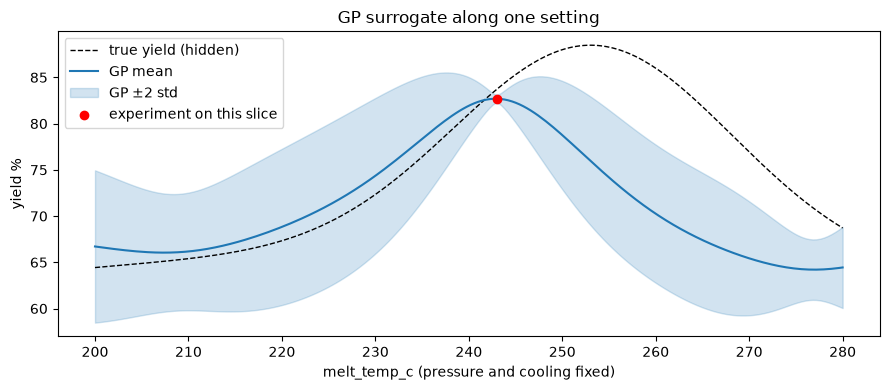

In [5]:
gp_hist = make_gp("matern_ard_noise").fit(U_hist, y_hist)
best_hist = X_hist[np.argmax(y_hist)]

temps = np.linspace(*BOUNDS["melt_temp_c"], 200)
slice_x = np.column_stack([temps, np.full(200, best_hist[1]), np.full(200, best_hist[2])])
mu, sd = gp_hist.predict(to_unit(slice_x), return_std=True)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(temps, true_yield(slice_x), "k--", lw=1, label="true yield (hidden)")
ax.plot(temps, mu, color="tab:blue", label="GP mean")
ax.fill_between(temps, mu - 2 * sd, mu + 2 * sd, color="tab:blue", alpha=0.2, label="GP ±2 std")
near = np.abs(X_hist[:, 1:] - best_hist[1:]).max(axis=1) < 1e-9
ax.scatter(X_hist[near, 0], y_hist[near], color="red", zorder=3, label="experiment on this slice")
ax.set_xlabel("melt_temp_c (pressure and cooling fixed)"); ax.set_ylabel("yield %")
ax.set_title("GP surrogate along one setting"); ax.legend(); plt.tight_layout(); plt.show()

The band is **narrow near the experiment** and **wide far from it**: that is the property Bayesian optimization exploits. Where the GP is unsure *and* the mean is promising, an experiment is most valuable.

But look closely: between ~245 and ~265 °C the hidden true yield runs **above the band**. With 12 points the GP has not seen the peak and is **over-confident** there. The next section measures this.

---
## 5. Are the error bars honest? Leave-one-out coverage

A GP's uncertainty is only useful if it is **calibrated**: about 95% of real outcomes should fall inside the ±1.96 std interval. With few points we check this with **leave-one-out (LOO)**: fit on 11 experiments, predict the 12th, repeat for each.

(Industry note: if coverage is much too low, the GP is over-confident: typical fixes are a noise term, a less smooth kernel, or a prior on the length-scales.)

In [6]:
def loo_check(X_unit, y, kernel_name="matern_ard_noise"):
    """Leave-one-out predictions, z-scores and 95% coverage."""
    rows = []
    for i in range(len(y)):
        keep = np.arange(len(y)) != i
        gp = make_gp(kernel_name).fit(X_unit[keep], y[keep])
        m, s = gp.predict(X_unit[[i]], return_std=True)
        rows.append({"actual": y[i], "pred": m[0], "std": s[0]})
    df = pd.DataFrame(rows)
    df["z"] = (df["actual"] - df["pred"]) / df["std"]
    return df


loo = loo_check(U_hist, y_hist)
print(f"LOO RMSE: {np.sqrt(((loo.actual - loo.pred) ** 2).mean()):.2f} yield points")
print(f"95% interval coverage: {(loo.z.abs() <= 1.96).mean():.0%} (target ~95%)")
print(f"Mean |z|: {loo.z.abs().mean():.2f} (about 0.8 if the std is honest)")
loo.round(2)

LOO RMSE: 6.28 yield points
95% interval coverage: 83% (target ~95%)
Mean |z|: 1.56 (about 0.8 if the std is honest)


,actual,pred,std,z
0,65.20,68.92,4.75,-0.78
1,66.79,71.75,2.98,-1.66
2,64.76,68.34,3.97,-0.90
3,63.91,68.94,4.87,-1.03
4,72.12,68.66,4.23,0.82
5,82.71,67.77,2.06,7.25
6,67.97,66.18,3.99,0.45
7,67.15,68.64,4.99,-0.30
8,66.77,79.18,2.40,-5.17
9,68.84,68.86,4.98,-0.00


With only 12 experiments spread over a 3-D space, each left-out point is far from the others, so the LOO errors are large (RMSE ≈ 6 points). The real question is whether the **uncertainty admits it**, and here it only partly does: coverage is ~83% instead of 95%, and the mean |z| is ~1.6 instead of ~0.8. Two experiments are badly missed: the **best** one (82.7%, z ≈ +7: no other point hinted at a peak there) and one the GP expected to be good. So the GP is **over-confident** on this small dataset.

That is common and not fatal for optimization (BO will go and measure the promising region anyway), but it means: never quote the GP's error bars from 12 points as guarantees. On 12 points this check is itself noisy (one miss changes coverage by 8 points). We re-check it after the optimization.

---
## 6. Expected Improvement in a few readable lines

Bayesian optimization needs a rule to pick the next experiment: an **acquisition function**. The most popular one is **Expected Improvement (EI)**:

> "On average, by how much will this setting **beat the best yield we have seen so far**?"

For a GP prediction with mean *μ* and std *σ*, and current best *best*, EI has a closed form:

$$ \text{EI} = (\mu - best - \xi)\,\Phi(z) + \sigma\,\varphi(z), \qquad z = \frac{\mu - best - \xi}{\sigma} $$

where Φ and φ are the normal CDF and PDF, and ξ is a small "exploration bonus". EI is large where the mean is high (**exploitation**) **or** where the uncertainty is large (**exploration**), and it automatically balances the two.

In [7]:
def expected_improvement(mu: np.ndarray, sigma: np.ndarray, best: float, xi: float = CFG.ei_xi) -> np.ndarray:
    """Expected Improvement for MAXIMISATION. mu, sigma: GP mean and std at candidate settings."""
    sigma = np.maximum(sigma, 1e-9)              # avoid division by zero at already-measured points
    improvement = mu - best - xi                 # how much better than the best so far (on average)
    z = improvement / sigma
    return improvement * norm.cdf(z) + sigma * norm.pdf(z)


def without_noise(gp: GaussianProcessRegressor) -> GaussianProcessRegressor:
    """Copy of a fitted GP whose std describes the TRUE (noise-free) yield, not a single noisy run.

    scikit-learn's predict(return_std=True) includes the WhiteKernel noise. For EI we want the uncertainty
    about the process itself; otherwise EI never drops at settings we already measured and may pick them again.
    """
    latent = copy.deepcopy(gp)
    latent.kernel_.set_params(k2__noise_level=1e-10)     # k2 = the WhiteKernel part; the mean is unchanged
    return latent


# Tiny illustration: three candidates
demo = pd.DataFrame({"mu": [80.0, 78.0, 70.0], "sigma": [0.5, 3.0, 8.0]})
demo["EI (best=79)"] = expected_improvement(demo["mu"].to_numpy(), demo["sigma"].to_numpy(), best=79.0).round(3)
demo.index = ["sure & slightly better", "unsure & a bit worse", "very unsure & much worse"]
demo

,mu,sigma,EI (best=79)
sure & slightly better,80.0,0.5,0.199
unsure & a bit worse,78.0,3.0,0.453
very unsure & much worse,70.0,8.0,0.405


Read the three rows: the first candidate is almost surely a little better than the current best of 79, yet it has the **lowest** EI. Why? With our exploration bonus ξ = 1 point (about one noise standard deviation), a gain of 1 point is "not worth chasing": it would be hard to even measure. The second candidate has a mean **below** the current best, but it **might** be several points better, so it gets the **highest** EI (**exploration**). This balance is what makes BO more efficient than "always try the best guess".

One practical detail (the `without_noise` helper above): scikit-learn's predicted std includes the measurement noise. For EI we use the uncertainty about the **true** yield, so that settings we already measured get a small EI and are not proposed again and again.

---
## 7. The Bayesian optimization loop (20 experiments)

The loop, exactly as it would run in the plant (each "round" = one day of experiments):

```
1. Run 6 space-filling experiments (Latin hypercube), no model yet.
2. Repeat until the budget of 20 experiments is used:
     fit the GP on all experiments so far
     score 4,096 candidate settings with Expected Improvement
     run the experiment with the highest EI and record the yield
3. Recommend the setting with the highest GP MEAN among the tried settings
   (not simply the highest noisy measurement: it might have been a lucky run).
```

In [8]:
def recommend(gp, X_tried):
    """Pick the tried setting with the best predicted (noise-free) yield."""
    return X_tried[[np.argmax(gp.predict(to_unit(X_tried)))]]        # keep 2-D shape (1, 3)


def bayesian_optimization(seed: int, budget: int = CFG.budget, verbose: bool = False):
    rng = np.random.default_rng(seed)
    X = from_unit(qmc.LatinHypercube(d=3, seed=seed).random(CFG.n_initial))     # step 1: initial design
    y = run_experiment(X, rng)
    candidates = qmc.Sobol(d=3, seed=seed).random(CFG.n_candidates)             # candidate settings in [0, 1]
    log_rows = []
    while len(y) < budget:
        gp = make_gp(seed=seed, restarts=2).fit(to_unit(X), y)                  # fit surrogate
        mu, sd = without_noise(gp).predict(candidates, return_std=True)         # uncertainty about the true yield
        ei = expected_improvement(mu, sd, best=y.max())
        x_next = from_unit(candidates[np.argmax(ei)])                           # most promising experiment
        y_next = run_experiment(x_next, rng)                                     # pay for it
        X, y = np.vstack([X, x_next]), np.append(y, y_next)
        log_rows.append({"experiment": len(y), **dict(zip(SETTINGS, x_next[0].round(1))),
                         "measured_yield": round(float(y_next[0]), 2), "max_EI": round(float(ei.max()), 3)})
    gp = make_gp(seed=seed, restarts=2).fit(to_unit(X), y)
    return X, y, gp, pd.DataFrame(log_rows)


t0 = time.perf_counter()
X_bo, y_bo, gp_bo, bo_log = bayesian_optimization(seed=0)
log.info("BO run finished in %.1fs", time.perf_counter() - t0)
best_x = recommend(gp_bo, X_bo)
print(f"Recommended setting: {dict(zip(SETTINGS, best_x[0].round(1)))}")
print(f"True yield there: {true_yield(best_x)[0]:.1f}% (best possible {BEST_POSSIBLE:.1f}%)")
bo_log

2026-10-21 17:22:15,764 | INFO | BO run finished in 7.6s


Recommended setting: {'melt_temp_c': np.float64(253.0), 'pressure_bar': np.float64(117.4), 'cooling_s': np.float64(20.7)}
True yield there: 89.3% (best possible 89.8%)


,experiment,melt_temp_c,pressure_bar,cooling_s,measured_yield,max_EI
0,7,236.8,68.0,10.4,67.31,0.004
1,8,234.2,89.6,39.9,67.25,0.003
2,9,234.0,120.6,24.3,76.41,0.002
3,10,271.6,132.9,24.3,68.19,0.076
4,11,236.6,91.9,23.3,68.14,0.051
5,12,237.5,124.8,24.8,80.17,0.039
6,13,238.7,133.1,13.2,69.18,0.294
7,14,240.7,122.6,24.6,82.78,0.070
8,15,243.2,127.1,23.4,83.73,0.133
9,16,247.4,125.2,25.4,84.23,0.205


Read the log from top to bottom: the first BO experiments probe different regions (**exploration**), then they move into the 240-255 °C / 112-125 bar / ~20-25 s region and the measured yield climbs from ~67% to ~89% (**exploitation**), with occasional "checks" elsewhere (e.g. 140 bar). In this run the recommended setting is within about half a point of the best possible yield.

The `max_EI` column is **not** monotonic: it can rise again when a new experiment reveals a promising direction. A practical **stopping signal** is when the max EI stays well below the measurement noise for several rounds: further experiments are then hardly worth $1,500 each.

---
## 8. Fair comparison: BO vs random vs grid search, 10 repeats

One run proves nothing. We repeat the whole 20-experiment campaign **10 times** (different initial designs and noise) for three strategies with **exactly the same budget**:

- **Random search**: 20 random settings.
- **Grid search**: a 3 × 3 × 2 grid (18 settings) + 2 repeats of the centre point = 20. This is what many plants do in practice (a "design of experiments" without adaptivity).
- **Bayesian optimization**: 6 initial + 14 EI-chosen settings.

For each campaign we record the **true** yield of the *recommended* setting (we can do that only because this is a simulation). For random and grid search the recommendation is simply the best measured experiment.

In [9]:
def random_search(seed: int, budget: int = CFG.budget):
    rng = np.random.default_rng(seed + 1000)
    X = from_unit(rng.random((budget, 3)))
    y = run_experiment(X, rng)
    return X, y


def grid_search(seed: int):
    rng = np.random.default_rng(seed + 2000)
    levels = [np.linspace(0.15, 0.85, 3), np.linspace(0.15, 0.85, 3), np.array([0.3, 0.7])]   # avoid extreme corners
    grid = np.array(np.meshgrid(*levels)).reshape(3, -1).T                 # 3 x 3 x 2 = 18 settings
    grid = np.vstack([grid, [[0.5, 0.5, 0.5]] * 2])                        # + 2 centre-point replicates = 20
    X = from_unit(grid)
    return X, run_experiment(X, rng)


def best_so_far_true(X, y):
    """True yield of the best-MEASURED experiment after each experiment (a 'learning curve')."""
    return np.array([true_yield(X[np.argmax(y[: i + 1])])[0] for i in range(len(y))])


t0 = time.perf_counter()
rows, curves = [], {"bayes_opt": [], "random": [], "grid": []}
for seed in range(CFG.n_repeats):
    Xb, yb, gpb, _ = bayesian_optimization(seed)
    Xr, yr = random_search(seed)
    Xg, yg = grid_search(seed)
    rows.append({"seed": seed,
                 "bayes_opt": true_yield(recommend(gpb, Xb))[0],
                 "random": true_yield(Xr[np.argmax(yr)])[0],
                 "grid": true_yield(Xg[np.argmax(yg)])[0]})
    curves["bayes_opt"].append(best_so_far_true(Xb, yb))
    curves["random"].append(best_so_far_true(Xr, yr))
    curves["grid"].append(best_so_far_true(Xg, yg))
log.info("%d campaigns x 3 strategies done in %.0fs", CFG.n_repeats, time.perf_counter() - t0)

comparison = pd.DataFrame(rows).set_index("seed")
print(comparison.round(1))
summary = comparison.agg(["mean", "std", "min"]).T
summary["gap_to_best_possible"] = BEST_POSSIBLE - summary["mean"]
summary["campaigns_within_2pts_of_best"] = (comparison >= BEST_POSSIBLE - 2).sum()
print("\n", summary.round(2))

2026-10-21 17:23:07,350 | INFO | 10 campaigns x 3 strategies done in 51s


      bayes_opt  random  grid
seed                         
0          89.3    79.4  81.3
1          89.3    70.7  81.3
2          88.4    77.2  81.3
3          89.2    83.3  81.3
4          88.6    88.6  81.3
5          89.3    79.9  81.3
6          88.5    82.1  81.3
7          89.4    89.7  81.3
8          89.0    77.4  81.3
9          86.4    87.6  81.3

             mean   std    min  gap_to_best_possible  \
bayes_opt  88.75  0.90  86.41                  1.02   
random     81.60  5.94  70.67                  8.17   
grid       81.27  0.00  81.27                  8.50   

           campaigns_within_2pts_of_best  
bayes_opt                              9  
random                                 2  
grid                                   0  


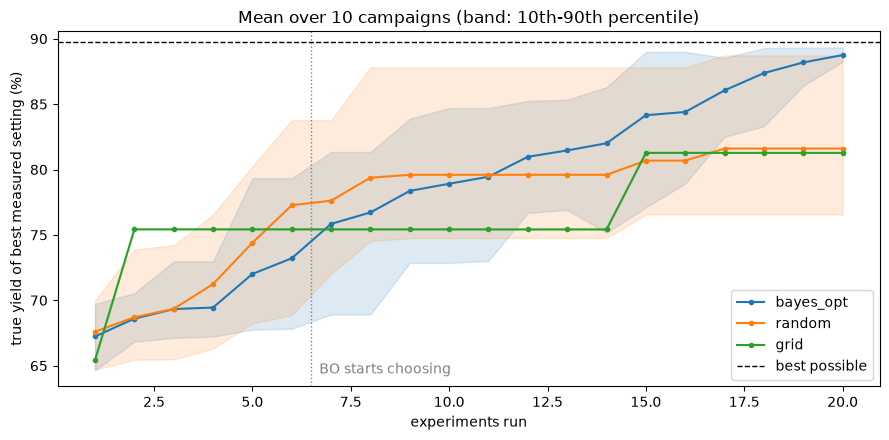

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x_axis = np.arange(1, CFG.budget + 1)
for name, color in [("bayes_opt", "tab:blue"), ("random", "tab:orange"), ("grid", "tab:green")]:
    arr = np.array(curves[name])
    ax.plot(x_axis, arr.mean(axis=0), color=color, marker=".", label=name)
    ax.fill_between(x_axis, np.percentile(arr, 10, axis=0), np.percentile(arr, 90, axis=0), color=color, alpha=0.15)
ax.axhline(BEST_POSSIBLE, color="k", ls="--", lw=1, label="best possible")
ax.axvline(CFG.n_initial + 0.5, color="grey", ls=":", lw=1)
ax.text(CFG.n_initial + 0.7, ax.get_ylim()[0] + 1, "BO starts choosing", color="grey")
ax.set_xlabel("experiments run"); ax.set_ylabel("true yield of best measured setting (%)")
ax.set_title("Mean over 10 campaigns (band: 10th-90th percentile)"); ax.legend(); plt.tight_layout(); plt.show()

**What the comparison shows** (numbers from the table above):
- **Bayesian optimization** ends about **1 point** below the best possible yield on average (≈88.8% vs 89.8%), with 9 of 10 campaigns within 2 points of the optimum and the best worst case (≈86%).
- **Random search** averages ≈81.6% and is sometimes lucky, sometimes not (worst campaign ≈71%).
- **Grid search** gives ≈81.3% every time: predictable, but its fixed levels simply miss the optimum (the true optimum is not on the grid), and it spends experiments in obviously bad regions. (Its curve has a jump at experiment 15 only because of the order in which the grid points are run.)
- In the **curve**, random search is actually ahead during the first ~10 experiments: BO's first 6 are a space-filling design and its first EI picks explore. BO overtakes around experiment 11 and reaches random search's final level after ~14 experiments.

In money terms: each experiment costs $1,500, so reaching the same quality ~6 experiments earlier saves ~$9,000 per campaign, and BO ends ~7 points of yield higher. Every percentage point of yield is worth much more than that over a production run of millions of parts.

> **A lesson from building this notebook:** with a much smaller exploration bonus (ξ = 0.05) one of the ten campaigns got stuck in a weaker region (~78%), because the over-confident GP stopped exploring. Setting ξ to about one noise standard deviation fixed it. BO has settings too, and they deserve a sanity check on a simulator like this one before a real campaign.

**Honest caveats:** BO's advantage is largest for **expensive**, **low-dimensional** (roughly ≤ 10-20 settings), **smooth** problems. For cheap evaluations or many dimensions, random search or evolutionary methods are often just as good and much simpler.

---
## 9. Recommending the next experiments (also in parallel batches)

The engineer does not want a black box: they want to see the **top candidates** with the predicted yield, the uncertainty and the EI, and they may veto a setting (e.g. "pressure above 135 bar wears the mold").

Many plants have **several machines**, so they run **3 experiments in parallel**. A simple, widely used trick for picking a batch is the **"kriging believer"**: pick the best EI point, pretend its result will equal the GP mean, refit (keeping the kernel fixed), and pick the next one. The fake point lowers the uncertainty around the first choice, so the second choice goes somewhere else.

In our run the top candidate refines the best region (predicted ≈87%, small std), while the other top candidates are **exploratory** (very high temperature with low pressure and short cooling, std 5-7 points). The parallel batch mixes one refinement with two far-away exploration points. This is where the engineer's judgement comes in: an extreme corner might be vetoed for safety or tool-wear reasons.

In [11]:
candidates = qmc.Sobol(d=3, seed=123).random(CFG.n_candidates)
mu_c, sd_c = without_noise(gp_bo).predict(candidates, return_std=True)
ei_c = expected_improvement(mu_c, sd_c, best=y_bo.max())
top = np.argsort(-ei_c)[:5]
top_table = pd.DataFrame(from_unit(candidates[top]).round(1), columns=SETTINGS)
top_table["pred_yield"] = mu_c[top].round(2)
top_table["pred_std"] = sd_c[top].round(2)
top_table["EI"] = ei_c[top].round(4)
print("Top-5 single next experiments by EI:")
print(top_table.to_string(index=False))


def kriging_believer_batch(gp, X_unit, y, cands, batch_size=3):
    """Pick a batch of experiments for parallel machines by 'believing' the GP mean at each pick."""
    X_fake, y_fake, picks = X_unit.copy(), y.copy(), []
    for _ in range(batch_size):
        believer = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True)   # keep fitted kernel
        believer = without_noise(believer.fit(X_fake, y_fake))
        m, s = believer.predict(cands, return_std=True)
        i = int(np.argmax(expected_improvement(m, s, best=y.max())))
        picks.append(cands[i])
        X_fake, y_fake = np.vstack([X_fake, cands[i]]), np.append(y_fake, m[i])      # pretend result = mean
    return from_unit(np.array(picks))


batch = kriging_believer_batch(gp_bo, to_unit(X_bo), y_bo, candidates)
print("\nBatch of 3 experiments for 3 machines (kriging believer):")
print(pd.DataFrame(batch.round(1), columns=SETTINGS).to_string(index=False))

Top-5 single next experiments by EI:
 melt_temp_c  pressure_bar  cooling_s  pred_yield  pred_std     EI
       255.5         111.4       23.1       87.34      2.37 0.0811
       268.9         102.6       13.0       78.36      6.50 0.0713
       269.1          99.8       12.1       77.57      6.82 0.0702
       274.9          99.0       11.8       76.38      7.33 0.0697
       266.0         105.5       16.3       81.05      5.28 0.0697

Batch of 3 experiments for 3 machines (kriging believer):
 melt_temp_c  pressure_bar  cooling_s
       255.5         111.4       23.1
       276.3          96.2       11.4
       201.4         135.2       38.9


---
## 10. The final recommendation and confirmation runs

After the campaign, the recommendation is the setting with the highest **predicted** yield (the GP mean smooths out lucky or unlucky measurements). Good practice before changing the production recipe:
1. Report the prediction **with its uncertainty**.
2. Run **3 confirmation replicates** at the recommended setting. If they disagree with the prediction, the model is missing something (drift, a different material batch, ...).
3. Check that the setting lies **inside** the explored region (not an extrapolation).

We also re-check the **calibration** of the GP's uncertainty, now with 20 experiments.

In [12]:
rec = recommend(gp_bo, X_bo)
rec_mu, rec_sd = without_noise(gp_bo).predict(to_unit(rec), return_std=True)   # uncertainty of the MEAN yield
confirm = run_experiment(np.repeat(rec, 3, axis=0), np.random.default_rng(99))

print("Recommended recipe:", dict(zip(SETTINGS, rec[0].round(1))))
print(f"Predicted yield: {rec_mu[0]:.1f}% ± {1.96 * rec_sd[0]:.1f} (95% interval for the mean)")
print(f"Confirmation runs: {confirm.round(1)} -> mean {confirm.mean():.1f}%")
print(f"(Hidden truth: {true_yield(rec)[0]:.1f}%; best possible {BEST_POSSIBLE:.1f}%)")

loo_final = loo_check(to_unit(X_bo), y_bo)
print(f"\nLOO 95% coverage with {len(y_bo)} experiments: {(loo_final.z.abs() <= 1.96).mean():.0%} | "
      f"LOO RMSE {np.sqrt(((loo_final.actual - loo_final.pred) ** 2).mean()):.2f} points")

Recommended recipe: {'melt_temp_c': np.float64(253.0), 'pressure_bar': np.float64(117.4), 'cooling_s': np.float64(20.7)}
Predicted yield: 89.7% ± 0.5 (95% interval for the mean)
Confirmation runs: [89.4 88.8 89.4] -> mean 89.2%
(Hidden truth: 89.3%; best possible 89.8%)



LOO 95% coverage with 20 experiments: 90% | LOO RMSE 3.73 points


Compare the confirmation runs with the prediction interval. Note that the interval printed is for the **mean** yield; single runs also include the ±1 point measurement noise, so they may scatter a bit more.

The LOO check on the final data is interesting: BO places most experiments close together near the optimum, so the GP predicts those well, while the few far-away exploration points are hard to predict. Calibration checks on BO data are therefore **biased by design**; keep that in mind before quoting them as model accuracy.

---
## 11. Save the surrogate with its metadata

The GP is small (it stores its training points), so it is easy to keep with the experiment log. We save it to a temporary folder; in a real project this would be `models/molding_process/product_X/v1/`, next to the lab notebook or MES data.

In [13]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="process_gp_"))         # real life: models/molding_process/v1/
joblib.dump(gp_bo, ARTIFACT_DIR / "gp_surrogate.joblib")
experiments = pd.DataFrame(X_bo.round(2), columns=SETTINGS).assign(yield_pct=y_bo.round(2))
experiments.to_csv(ARTIFACT_DIR / "experiments.csv", index_label="experiment")
metadata = {
    "model_name": "molding_yield_gp",
    "model_version": "1.0.0",
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "bounds": BOUNDS,
    "input_order": SETTINGS,
    "input_scaling": "unit cube using fixed bounds",
    "fitted_kernel": str(gp_bo.kernel_),
    "n_experiments": int(len(y_bo)),
    "recommended_setting": dict(zip(SETTINGS, rec[0].round(2).tolist())),
    "predicted_yield": round(float(rec_mu[0]), 2),
    "config": asdict(CFG),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:22s} {f.stat().st_size / 1024:6.1f} KB")

experiments.csv           0.6 KB
gp_surrogate.joblib      10.6 KB
metadata.json             0.9 KB


---
## 12. Serving: predict yield for proposed settings, with input validation

Engineers will ask "what if we run at 260 °C, 120 bar, 20 s?". A small service answers with a prediction, an interval, and two safety checks:
- **Bounds**: settings outside the allowed range are rejected (the machine might be damaged, and the GP knows nothing there).
- **Extrapolation warning**: if the predicted std is large, the GP is guessing; the answer says so instead of sounding confident.

In [14]:
from pydantic import BaseModel, ValidationError, model_validator


class ProcessSettings(BaseModel):
    melt_temp_c: float
    pressure_bar: float
    cooling_s: float

    @model_validator(mode="after")
    def inside_bounds(self):
        for name, (low, high) in BOUNDS.items():
            value = getattr(self, name)
            if not low <= value <= high:
                raise ValueError(f"{name}={value} outside allowed range [{low}, {high}]")
        return self


class YieldPredictor:
    def __init__(self, artifact_dir: Path, max_trusted_std: float = 3.0):
        self.gp = without_noise(joblib.load(artifact_dir / "gp_surrogate.joblib"))   # intervals for the mean yield
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())
        self.max_trusted_std = max_trusted_std                    # yield points

    def predict(self, settings: dict) -> dict:
        s = ProcessSettings(**settings)                           # raises ValidationError if out of bounds
        x = np.array([[getattr(s, k) for k in self.meta["input_order"]]])
        mu, sd = self.gp.predict(to_unit(x), return_std=True)
        return {"predicted_yield_pct": round(float(mu[0]), 2),
                "interval_95": [round(float(mu[0] - 1.96 * sd[0]), 2), round(float(mu[0] + 1.96 * sd[0]), 2)],
                "trustworthy": bool(sd[0] <= self.max_trusted_std),
                "note": "inside explored region" if sd[0] <= self.max_trusted_std
                        else "far from past experiments: run an experiment before trusting this"}


predictor = YieldPredictor(ARTIFACT_DIR)
print("Recommended :", predictor.predict(metadata["recommended_setting"]))
print("Far corner  :", predictor.predict({"melt_temp_c": 200, "pressure_bar": 140, "cooling_s": 10}))
try:
    predictor.predict({"melt_temp_c": 320, "pressure_bar": 100, "cooling_s": 20})
except ValidationError as err:
    print("Rejected    :", err.errors()[0]["msg"])

Recommended : {'predicted_yield_pct': 89.69, 'interval_95': [89.17, 90.21], 'trustworthy': True, 'note': 'inside explored region'}
Far corner  : {'predicted_yield_pct': 70.18, 'interval_95': [55.65, 84.71], 'trustworthy': False, 'note': 'far from past experiments: run an experiment before trusting this'}
Rejected    : Value error, melt_temp_c=320.0 outside allowed range [200.0, 280.0]


---
## 13. Automated tests

In [15]:
def test_ei_is_non_negative_and_prefers_uncertainty():
    ei = expected_improvement(np.array([70.0, 70.0]), np.array([0.1, 5.0]), best=75.0)
    assert (ei >= 0).all() and ei[1] > ei[0]


def test_scaling_roundtrip():
    x = np.array([[230.0, 100.0, 25.0]])
    assert np.allclose(from_unit(to_unit(x)), x)


def test_bo_respects_budget_and_bounds():
    assert len(y_bo) == CFG.budget
    assert ((X_bo >= LOW - 1e-9) & (X_bo <= HIGH + 1e-9)).all()


def test_out_of_bounds_request_is_rejected():
    try:
        predictor.predict({"melt_temp_c": 150, "pressure_bar": 100, "cooling_s": 20})
    except Exception:
        return
    raise AssertionError("out-of-bounds settings were accepted")


def test_bo_beats_random_on_average():
    assert comparison["bayes_opt"].mean() > comparison["random"].mean()


for test_fn in [test_ei_is_non_negative_and_prefers_uncertainty, test_scaling_roundtrip, test_bo_respects_budget_and_bounds,
                test_out_of_bounds_request_is_rejected, test_bo_beats_random_on_average]:
    test_fn()
    print(f"PASSED  {test_fn.__name__}")

PASSED  test_ei_is_non_negative_and_prefers_uncertainty
PASSED  test_scaling_roundtrip
PASSED  test_bo_respects_budget_and_bounds
PASSED  test_out_of_bounds_request_is_rejected
PASSED  test_bo_beats_random_on_average


---
## 14. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| GP as a surrogate | `GaussianProcessRegressor` on scaled inputs, `normalize_y=True` | Process engineering, chemistry, materials, simulations |
| Sensible kernel | Constant × Matern(2.5) with ARD + WhiteKernel noise | Default in BoTorch / most BO libraries |
| Check the uncertainty | Leave-one-out coverage and z-scores | Before trusting any error bar |
| Acquisition function | Expected Improvement in 4 lines | Bayesian optimization everywhere |
| Fair benchmark | BO vs random vs grid, same budget, 10 repeats | Proving the method is worth it |
| Recommend by mean, confirm by replicates | GP mean at tried points + 3 confirmation runs | Changing a production recipe safely |
| Parallel experiments | Kriging-believer batch | Several machines / lab robots |
| Safe serving | Bounds validation + extrapolation warning | Engineering "what-if" tools |

### Practice exercises
1. Set `noise_sd=3.0` (a noisier process). Does BO still beat random search? What does the `WhiteKernel` learn?
2. Replace EI with **Upper Confidence Bound**: `UCB = mu + 2 * sigma`. Compare the 10-campaign results.
3. Add a **known constraint**: cooling time must be ≤ 30 s because of the cycle-time target. (Hint: filter the candidate set.)
4. Use `optuna.samplers.GPSampler` (Optuna is in `requirements.txt`) to optimise the same `run_experiment` function and compare it with our hand-written loop.

### Resources
- scikit-learn user guide, *Gaussian Processes* (kernels, `normalize_y`, `WhiteKernel`): https://scikit-learn.org/stable/modules/gaussian_process.html
- scikit-learn example, *Gaussian Processes regression: basic introductory example*: https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_gpr_noisy_targets.html
- Peter Frazier (2018), *A Tutorial on Bayesian Optimization*: https://arxiv.org/abs/1807.02811
- Martin Krasser, *Bayesian optimization* notebook (NumPy/SciPy implementation of EI, plus scikit-optimize): https://github.com/krasserm/bayesian-machine-learning
- BoTorch / Ax (Meta's production BO libraries): https://botorch.org and https://ax.dev
- Snoek, Larochelle & Adams (2012), *Practical Bayesian Optimization of Machine Learning Algorithms*: https://arxiv.org/abs/1206.2944

### Related notebooks
- GP basics and other uncommon models: `01_uncommon_ml_models.ipynb`
- Bayesian optimisation for hyperparameters with Optuna: `../06_model_evaluation/02_hyperparameter_optimization.ipynb`
- Uncertainty with guarantees: `../14_conformal_prediction/01_conformal_prediction.ipynb`